In [269]:
%load_ext storemagic
%load_ext autoreload
%autoreload 2

%matplotlib widget
import json
import os
import pickle as pkl
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import clear_output
from loguru import logger
from tqdm.notebook import tqdm

from prl.classification import lesion_analysis as lesion_dx
from prl.core.dataset import Dataset
from prl.core.experiment import Experiment
from prl.core.inference import uncrop_predictions
from prl.helpers.parallel import BetterPool
from prl.helpers.shell_interface import open_itksnap_workspace_cmd
from prl.helpers.utils import dice_score, get_prl_indices, cached
from prl.scripts.compile_run_metrics import EXPERIMENT_KEYS, load_or_cache_run


The storemagic extension is already loaded. To reload it, use:
  %reload_ext storemagic
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [270]:
def get_infer_path(dataset, test_case, experiment_name) -> Path:
    case_dir = dataset.lesion_dir(test_case)
    matches = list(case_dir.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

    
def find_inference(search_path, experiment_name) -> Path:
    matches = list(search_path.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

In [271]:
dataset_name = "roi_train2"
dataset = Dataset(dataset_name)

experiment_key, run_name = "stage6", "run1"
experiment_name = f"{EXPERIMENT_KEYS[experiment_key]}/{run_name}"
# experiment_name = "sweep_dicecewts/run1"
# experiment_name = "test_dicece_lambda/run1"
experiment = Experiment.from_run_dir(experiment_name, dataset)

expand_xy: int = experiment.preprocess_config.expand_xy
expand_z: int = experiment.preprocess_config.expand_z
expand_str = f"xy{expand_xy}_z{expand_z}"
images: tuple[str, ...] = experiment.preprocess_config.images

experiment.show_input_config()

╭──────────────────────────────────── roi_train2/stage6_sweep_dicece_wts/run1 ────────────────────────────────────╮
│                                                                                                                 │
│  input.yaml                                                                                                     │
│  ├── modality: MRI                                                                                              │
│  ├── datalist:                                                                                                  │
│  │   /media/smbshare/srs-9/prl_project/training/roi_train2/stage6_sweep_dicece_wts/run1/datalist_flair.phase_x  │
│  │   y20_z2.json                                                                                                │
│  ├── dataroot: /media/smbshare/srs-9/prl_project/data                                                           │
│  ├── learning_rate: 0.0002                                                                                      │
│  ├── num_epochs: 500                                                                                            │
│  ├── num_images_per_batch: 1                                                                                    │
│  ├── batch_size: 1                                                                                              │
│  ├── num_warmup_epochs: 1                                                                                       │
│  ├── num_epochs_per_validation: 1                                                                               │
│  ├── num_epochs_per_saving: 1                                                                                   │
│  ├── num_crops_per_image: 1                                                                                     │
│  ├── num_workers: 4                                                                                             │
│  ├── roi_size: [44, 44, 8]                                                                                      │
│  ├── crop_mode: ratio                                                                                           │
│  ├── crop_foreground: True                                                                                      │
│  ├── auto_scale_allowed: False                                                                                  │
│  ├── auto_scale_batch: False                                                                                    │
│  ├── auto_scale_roi: False                                                                                      │
│  ├── auto_scale_filters: False                                                                                  │
│  ├── amp: True                                                                                                  │
│  ├── channels_last: True                                                                                        │
│  ├── determ: False                                                                                              │
│  ├── early_stopping_fraction: 0.001                                                                             │
│  └── loss                                                                                                       │
│      ├── _target_: DiceCELoss                                                                                   │
│      ├── include_background: True                                                                               │
│      ├── weight: $torch.tensor([1.0, 1.0, 10.0]).cuda()                                                         │
│      ├── squared_pred: True                                                                                     │
│      ├── smooth_nr: 0                                                                                           │
│      ├── smooth_dr: 1e-05                             

In [272]:
REBUILD = False
cache = Path("cache") / f"inference_{experiment.id}.pkl"

def find_all_inference(cases, experiment_name):
    return pd.Series(
        [find_inference(Path(c.subject_dir) / str(c.name[1]), experiment_name)
         for _, c in tqdm(cases.iterrows(), total=len(cases))],
        index=cases.index,
    ) 

def find_all_labels(cases):
    return pd.Series(
        [c.label if os.path.exists(c.label) else c.subject_dir/str(c.name[1])/f"lesion_{expand_str}.nii.gz"
         for _, c in tqdm(cases.iterrows(), total=len(cases))],
         index=cases.index
    )

inference_dataset = Dataset("inference_dataset")
cases = inference_dataset.cases
cases['inference'] = cached(cache, find_all_inference, cases, experiment_name)
cases['label'] = find_all_labels(cases)

  0%|          | 0/3912 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# all_results = {}

# for subid in tqdm(inference_dataset.cases.index.get_level_values("subid").unique()):
#     # screen for iron returns dict of {lesion_index: bool}
#     res = lesion_dx.screen_for_iron(inference_dataset, subid, "inference")
#     # Store with the full (subid, lesion_index) tuple key
#     for l_idx, val in res.items():
#         all_results[(subid, l_idx)] = val

# # Map the dictionary to the index to create the column all at once
# inference_dataset.cases['has_iron'] = inference_dataset.cases.index.map(all_results).fillna(False)
# screened_cases = inference_dataset.cases[inference_dataset.cases['has_iron']]

  0%|          | 0/52 [00:00<?, ?it/s]

In [273]:
def analyze_wrapper(args):
    dataset, subid, lesion_indices = args
    return lesion_dx.analyze_subject_prl(subid, dataset, "inference", lesion_indices=lesion_indices)

analysis_dir = Path("/home/srs-9/Projects/prl_project/analysis/")
savepath = analysis_dir/ f"prl_image_stats-{experiment.id.replace('/', '_')}.csv"
if not savepath.exists():
    full_data = defaultdict(list)
    tasks = []
    for subid, g in inference_dataset.cases.reset_index().groupby("subid"):
        tasks.append((inference_dataset, subid, g['lesion_index'].to_list()))
    with BetterPool(8) as pool:
        results_iterator = pool.imap_unordered(analyze_wrapper, tasks)
        for result in tqdm(results_iterator, total=len(tasks)):
            full_data['prl_stats'].extend(result[0])
            full_data['prl_data'].extend(result[1])

    feature_df = pd.DataFrame(full_data['prl_stats'])

    feature_df.to_csv(
        savepath,
        index=False
    )
else:
    feature_df = pd.read_csv(savepath)

feature_df = feature_df.rename(columns={c: f"my_features_{c}" for c in feature_df.columns if c not in ["subid", "lesion_index", "case_type", "has_iron_infer"]})


In [276]:
import subprocess

REBUILD = False
WORKER_SCRIPT = "/home/srs-9/Projects/prl_project/notebooks/radiomics_worker.py"
PYTHON_36 = "/home/srs-9/anaconda3/envs/pyradiomics2/bin/python"
inference_dataset.cases['has_iron'] = feature_df.set_index(["subid", "lesion_index"]).has_iron_infer

svname = f"{experiment.id.replace('/', '-')}-inference_pyradiomics.csv"
savepath = f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}"
if not os.path.exists(savepath) or REBUILD:
    # inference_dataset.cases = cases
    # cases = inference_dataset.cases[feature_df.set_index(["subid", "lesion_index"]).has_iron_infer]
    cases = inference_dataset.cases
    cases.groupby("subid")["has_iron"].sum()

    params_rim = "/home/srs-9/Projects/prl_project/notebooks/tmp/radiomics_params_rim.yaml"
    params_lesion = "/home/srs-9/Projects/prl_project/notebooks/tmp/radiomics_params_lesion.yaml"

    all_features = []
    for i in tqdm(range(len(cases))):
        lesion_case = cases.iloc[i]
        subid = lesion_case.name[0]
        lesion_index = lesion_case.name[1]
        lesion_dir = Path(lesion_case['image']).parent
        expand_suffix = f"_xy{inference_dataset.preprocess.expand_xy}_z{inference_dataset.preprocess.expand_z}"
        phase_path = lesion_dir / f"phase{expand_suffix}.nii.gz"
        inference_path = lesion_case['inference']
        gt_label_path = lesion_case['label']

        features = {}
        features['subid'] = subid
        features['lesion_index'] = lesion_index
        for params_label_key, params in [("rim", params_rim), ("lesion", params_lesion), ("lesion_infer", params_lesion)]: 
            if params_label_key in ["rim", "lesion_infer"]:
                mask_path = inference_path
            else:
                mask_path = gt_label_path
            input_data = {"image_path": str(phase_path), "mask_path": str(mask_path), "params": str(params)}
            with open("temp_in.json", "w") as f:
                json.dump(input_data, f)

            try:
                process = subprocess.run(
                    [PYTHON_36, WORKER_SCRIPT, "temp_in.json", "temp_out.json"],
                    capture_output=True,
                    check=True,
                    text=True,
                )
            except subprocess.CalledProcessError as e:
                print(e.stdout)
                print(subid, lesion_index, mask_path)
                print(e.stderr)
                continue

            with open("temp_out.json", 'r') as f:
                tmp_features = json.load(f)

            features.update({
                f"{params_label_key}_{k}": v for k,v in tmp_features.items()
            })
            
        all_features.append(features)
        
        
    all_features_df = pd.DataFrame(all_features)
    all_features_df = all_features_df.set_index(["subid", "lesion_index"])
    all_features_df.to_csv(savepath)
else:
    all_features_df = pd.read_csv(f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}")

all_features_df = all_features_df.rename(columns={c: f"pyradiomics_{c}" for c in all_features_df.columns if c not in ["subid", "lesion_index", "case_type", "has_iron_infer"]})

In [277]:
df = inference_dataset.cases.reset_index().merge(
    feature_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

df = df.merge(
    all_features_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

df.to_csv(f"{experiment.id.replace('/', '-')}-features_df.csv")

In [278]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

from prl.helpers import assign_prl_folds

RANDOM_STATE = SEED = 42


classifiers = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                    class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}

In [279]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate


RANDOM_STATE = SEED = 42


classifiers = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                    class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"

TEST_SIZE = 0.10

CLF = "LR"

df = pd.read_csv(f"{experiment.id.replace('/', '-')}-features_df.csv")
data = df.loc[df["case_type"].isin(["PRL", "Lesion"])].copy()
data["fold"] = assign_prl_folds(data, n_splits=5)

# Inspect the achieved balance.
summary = (
    data.assign(is_prl=data["case_type"].eq("PRL"))
    .groupby("fold")
    .agg(
        subjects=("subid", "nunique"),
        lesions=("lesion_index", "size"),
        prls=("is_prl", "sum"),
        prl_prevalence=("is_prl", "mean"),
    )
)
print(summary.round(3))

assert data.groupby("subid")["fold"].nunique().eq(1).all()

data = data.set_index(["subid", "lesion_index"])

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

# Separate lesions by SegResNet screening result.
screened_in = data.loc[data[SCREEN_COL]]
screened_out = data.loc[~data[SCREEN_COL]]

print("\nAfter Screening")
print(f"All lesions:  {len(data)} ({data.y_true.sum()} PRLs)")
print(f"Screened in:  {len(screened_in)} ({screened_in.y_true.sum()} PRLs)")
print(f"Screened out: {len(screened_out)} ({screened_out.y_true.sum()} PRLs)")

screen_sensitivity = screened_in.y_true.sum() / data.y_true.sum()
print(f"Rim-screen sensitivity: {screen_sensitivity:.1%}")

summary = (
    screened_in.reset_index().assign(is_prl=screened_in.reset_index()["case_type"].eq("PRL"))
    .groupby("fold")
    .agg(
        subjects=("subid", "nunique"),
        lesions=("lesion_index", "size"),
        prls=("is_prl", "sum"),
        prl_prevalence=("is_prl", "mean"),
    )
)
print(summary.round(3))


      subjects  lesions  prls  prl_prevalence
fold                                         
1            9      841    23           0.027
2           10      504    24           0.048
3           11      874    23           0.026
4           11      827    23           0.028
5           11      866    23           0.027

After Screening
All lesions:  3912 (116 PRLs)
Screened in:  442 (111 PRLs)
Screened out: 3470 (5 PRLs)
Rim-screen sensitivity: 95.7%
      subjects  lesions  prls  prl_prevalence
fold                                         
1            9       98    22           0.224
2           10       79    22           0.278
3           11       85    22           0.259
4           11       93    23           0.247
5           11       87    22           0.253


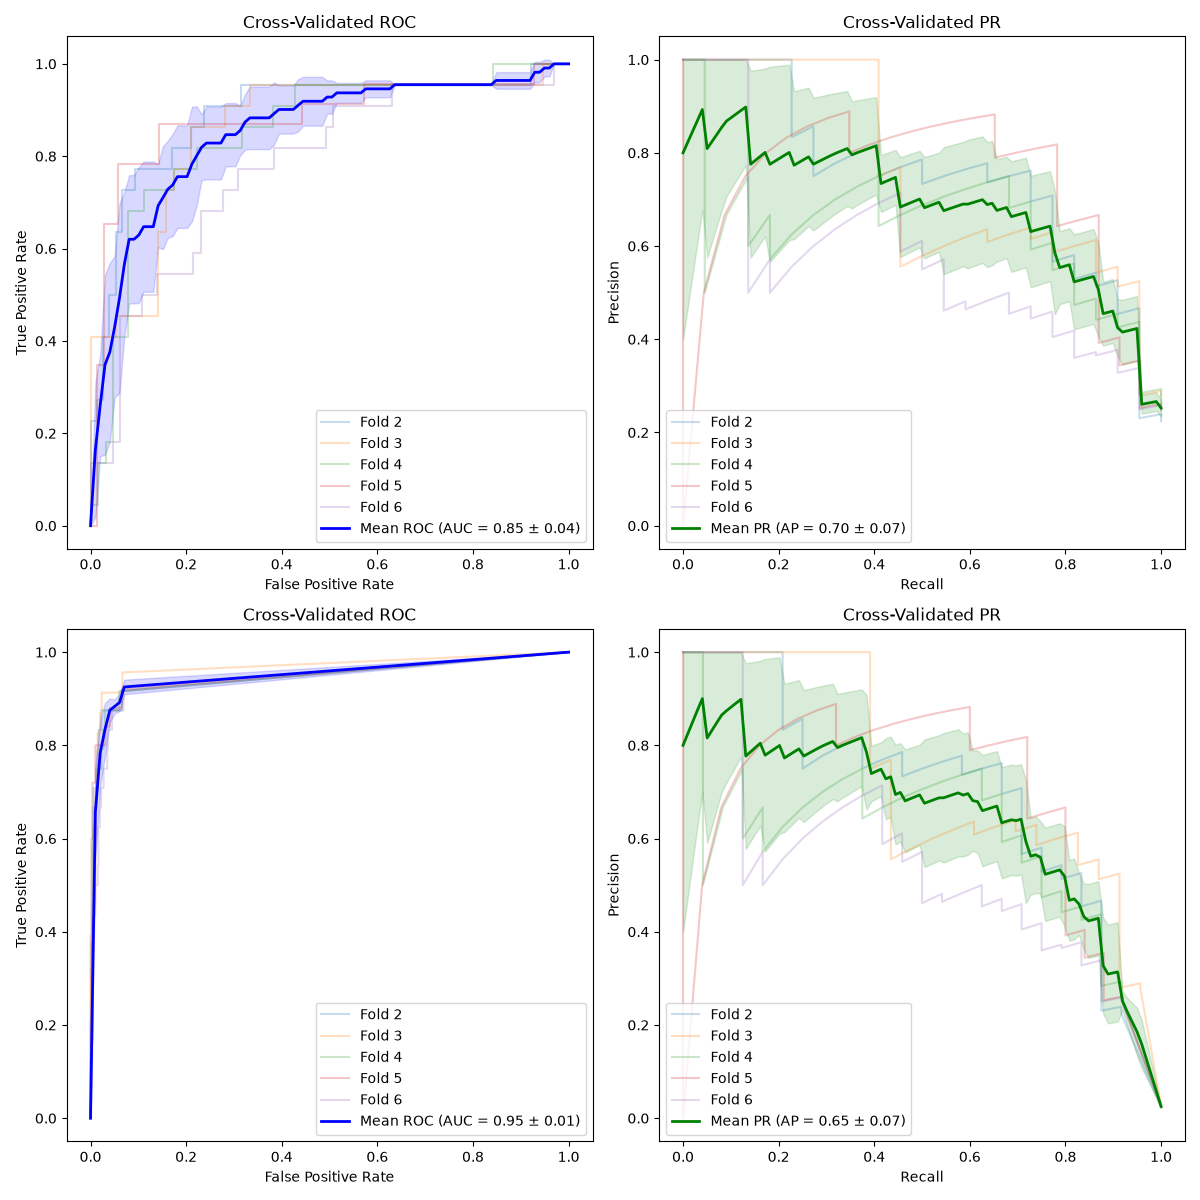

In [280]:
FEATURES = [
    "my_features_rim_volume_infer",
    "my_features_rim_hull_volume_infer",
    "my_features_rim_sphere_radius_infer",
    "my_features_pca_size",
    "my_features_pca_sphericity",
    "my_features_pca_planarity",
    "my_features_pca_linearity",
    "my_features_mean_radius",
    "my_features_std_radius",
    "my_features_min_radius",
    "my_features_max_radius",
    "my_features_radial_cv",
]
# FEATURES = [col for col in data.columns if "pyradiomics_lesion_" in col]

# %% Prepare data
# Keep lesion identifiers as the DataFrame index throughout.



model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", classifiers[CLF]),
])

# %% Split and train

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Grids for interpolation
mean_fpr = np.linspace(0, 1, 100)
mean_recall = np.linspace(0, 1, 100)

tprs_cond, aucs_cond, tprs_pipeline, aucs_pipeline = [], [], [], []
precisions_cond, aps_cond, precisions_pipeline, aps_pipeline = [], [], [], []

fig, axes = plt.subplots(2, 2, figsize=(12,12))
ax_roc_cond, ax_pr_cond = axes[0,:]
ax_roc_pipeline, ax_pr_pipeline = axes[1,:]


from scipy.special import expit

SCREEN_COL = "has_iron_infer"  # SegResNet prediction
data["y_true"] = data["case_type"].eq("PRL").astype(int)

# Assumes has_iron_infer is Boolean in the CSV.
data[SCREEN_COL] = data[SCREEN_COL].fillna(False)
if not pd.api.types.is_bool_dtype(data[SCREEN_COL]):
    raise ValueError(f"{SCREEN_COL} must contain Boolean values.")

for fold, test_df in data.groupby("fold"):
    # Stage 2 sees only screen-positive lesions from training subjects.
    train_candidates = data.loc[data["fold"].ne(fold) & data[SCREEN_COL]]
    model.fit(train_candidates[FEATURES], train_candidates["y_true"])

    # Every lesion from the held-out subjects belongs in the full evaluation.
    passed = test_df[SCREEN_COL]
    pipeline_test = test_df[["y_true"]].copy()
    pipeline_test["score"] = 0.0

    if passed.any():
        X_test = test_df.loc[passed, FEATURES]

        if CLF == "SVM":
            # Map SVC margins to positive ranking scores above screen rejects.
            # These scores are not calibrated probabilities.
            scores = expit(model.decision_function(X_test))
        else:
            scores = model.predict_proba(X_test)[:, 1]

        pipeline_test.loc[passed, "score"] = scores

    # Conditional evaluation uses the same predictions, restricted to candidates.
    conditional_test = pipeline_test.loc[passed]

    # --- Conditional ---

    #   # --- ROC Curve ---
    fpr, tpr, _ = roc_curve(conditional_test['y_true'], conditional_test['score'])
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs_cond.append(interp_tpr)
    aucs_cond.append(auc(fpr, tpr))
    ax_roc_cond.plot(fpr, tpr, alpha=0.25, label=f"Fold {fold+1}")

    #   # --- PR Curve ---
    prec, rec, _ = precision_recall_curve(conditional_test['y_true'], conditional_test['score'])
    # Reverse arrays so recall is strictly increasing for np.interp
    interp_prec = np.interp(mean_recall, rec[::-1], prec[::-1])
    precisions_cond.append(interp_prec)
    aps_cond.append(average_precision_score(conditional_test['y_true'], conditional_test['score']))
    ax_pr_cond.plot(rec, prec, alpha=0.25, label=f"Fold {fold+1}")

    # --- Full Pipeline ---

    # Sample the same fraction of screened-out lesions.
    rejected_test = screened_out.sample(
        frac=(X_test.shape[0]/train_candidates.shape[0]),
        random_state=fold,
    )[["y_true"]].copy()
    
    # Hard screening rule: lesions without predicted rims receive score 0.
    rejected_test["score"] = 0.0

    # Combine both sets while preserving (subid, lesion_index).
    pipeline_test = pd.concat([conditional_test, rejected_test])
    pipeline_test = pipeline_test.sort_index()

    #   # --- ROC Curve ---
    fpr, tpr, _ = roc_curve(pipeline_test['y_true'], pipeline_test['score'])
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs_pipeline.append(interp_tpr)
    aucs_pipeline.append(auc(fpr, tpr))
    ax_roc_pipeline.plot(fpr, tpr, alpha=0.25, label=f"Fold {fold+1}")

    #   # --- PR Curve ---
    prec, rec, _ = precision_recall_curve(pipeline_test['y_true'], pipeline_test['score'])
    # Reverse arrays so recall is strictly increasing for np.interp
    interp_prec = np.interp(mean_recall, rec[::-1], prec[::-1])
    precisions_pipeline.append(interp_prec)
    aps_pipeline.append(average_precision_score(pipeline_test['y_true'], pipeline_test['score']))
    ax_pr_pipeline.plot(rec, prec, alpha=0.25, label=f"Fold {fold+1}")


# --- Plot Conditional Results ---
#   # --- Plot Mean ROC + Std Band  ---
mean_tpr_cond = np.mean(tprs_cond, axis=0)
mean_tpr_cond[-1] = 1.0
std_tpr = np.std(tprs_cond, axis=0)
ax_roc_cond.plot(mean_fpr, mean_tpr_cond, color="b", lw=2,
            label=f"Mean ROC (AUC = {np.mean(aucs_cond):.2f} ± {np.std(aucs_cond):.2f})")
ax_roc_cond.fill_between(mean_fpr, mean_tpr_cond - std_tpr, mean_tpr_cond + std_tpr, color="b", alpha=0.15)
ax_roc_cond.set(title="Cross-Validated ROC", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax_roc_cond.legend(loc="lower right")

#   # ---Plot Mean PR + Std Band ---
mean_prec_cond = np.mean(precisions_cond, axis=0)
std_prec = np.std(precisions_cond, axis=0)
ax_pr_cond.plot(mean_recall, mean_prec_cond, color="g", lw=2,
           label=f"Mean PR (AP = {np.mean(aps_cond):.2f} ± {np.std(aps_cond):.2f})")
ax_pr_cond.fill_between(mean_recall, np.maximum(mean_prec_cond - std_prec, 0),
                   np.minimum(mean_prec_cond + std_prec, 1), color="g", alpha=0.15)
ax_pr_cond.set(title="Cross-Validated PR", xlabel="Recall", ylabel="Precision")
ax_pr_cond.legend(loc="lower left")

# --- Plot Pipeline Results ---
#   # --- Plot Mean ROC + Std Band  ---
mean_tpr_pipeline = np.mean(tprs_pipeline, axis=0)
mean_tpr_pipeline[-1] = 1.0
std_tpr = np.std(tprs_pipeline, axis=0)
ax_roc_pipeline.plot(mean_fpr, mean_tpr_pipeline, color="b", lw=2,
            label=f"Mean ROC (AUC = {np.mean(aucs_pipeline):.2f} ± {np.std(aucs_pipeline):.2f})")
ax_roc_pipeline.fill_between(mean_fpr, mean_tpr_pipeline - std_tpr, mean_tpr_pipeline + std_tpr, color="b", alpha=0.15)
ax_roc_pipeline.set(title="Cross-Validated ROC", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax_roc_pipeline.legend(loc="lower right")

#   # ---Plot Mean PR + Std Band ---
mean_prec_pipeline = np.mean(precisions_pipeline, axis=0)
std_prec = np.std(precisions_pipeline, axis=0)
ax_pr_pipeline.plot(mean_recall, mean_prec_pipeline, color="g", lw=2,
           label=f"Mean PR (AP = {np.mean(aps_pipeline):.2f} ± {np.std(aps_pipeline):.2f})")
ax_pr_pipeline.fill_between(mean_recall, np.maximum(mean_prec_pipeline - std_prec, 0),
                   np.minimum(mean_prec_pipeline + std_prec, 1), color="g", alpha=0.15)
ax_pr_pipeline.set(title="Cross-Validated PR", xlabel="Recall", ylabel="Precision")
ax_pr_pipeline.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [268]:
from sklearn import metrics
from math import floor
from prl.analysis.metrics import performance
thresh = 0.5

def classification_results(y_true, y_pred):
    pass

conditional_test['y_pred'] = (conditional_test["score"] >= thresh).astype(int)
nTN, nFP, nFN, nTP = confusion_matrix(
    conditional_test["y_true"], conditional_test["y_pred"], labels=[0, 1]
).ravel()

performance.compute_derived_metrics(nTP, nFP, nTN, nFN)

{'sensitivity': np.float64(0.5909090909090909),
 'specificity': np.float64(0.7692307692307693),
 'fpr': np.float64(0.23076923076923078),
 'fnr': np.float64(0.4090909090909091),
 'precision': np.float64(0.4642857142857143),
 'npv': np.float64(0.847457627118644),
 'accuracy': np.float64(0.7241379310344828),
 'f1': np.float64(0.52)}

In [267]:
confusion_matrix(
    conditional_test["y_true"], conditional_test["y_pred"], labels=[0, 1]
).ravel()

array([50, 15,  9, 13])

In [233]:
(conditional_test['score']).floordiv(0.5).astype(bool).astype(int)

subid  lesion_index
1082   10              0
1376   4               1
1183   1               1
1292   6               0
1274   1               1
                      ..
1183   3               1
1178   3               0
1183   7               0
1292   2               1
1453   8               1
Name: score, Length: 87, dtype: int64

/tmp/ipykernel_2145434/7205974.py:29: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  data = pd.read_csv(CSV).set_index(["subid", "lesion_index"], verify_integrity=True)
/home/srs-9/Projects/prl_project/.venv/lib/python3.13/site-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home/srs-9/Projects/prl_project/.venv/lib/python3.13/site-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home/srs-9/Projects/prl_project/.venv/lib/python3.13/site-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matp

has_iron_infer  False  True 
case_type                   
Lesion           3465    331
PRL                 5    111
Screen sensitivity: 95.7%
                        Lesions  PRLs  ROC AUC     AP
Evaluation                                           
Conditional classifier      442   111    0.830  0.670
Full pipeline              3912   116    0.962  0.643


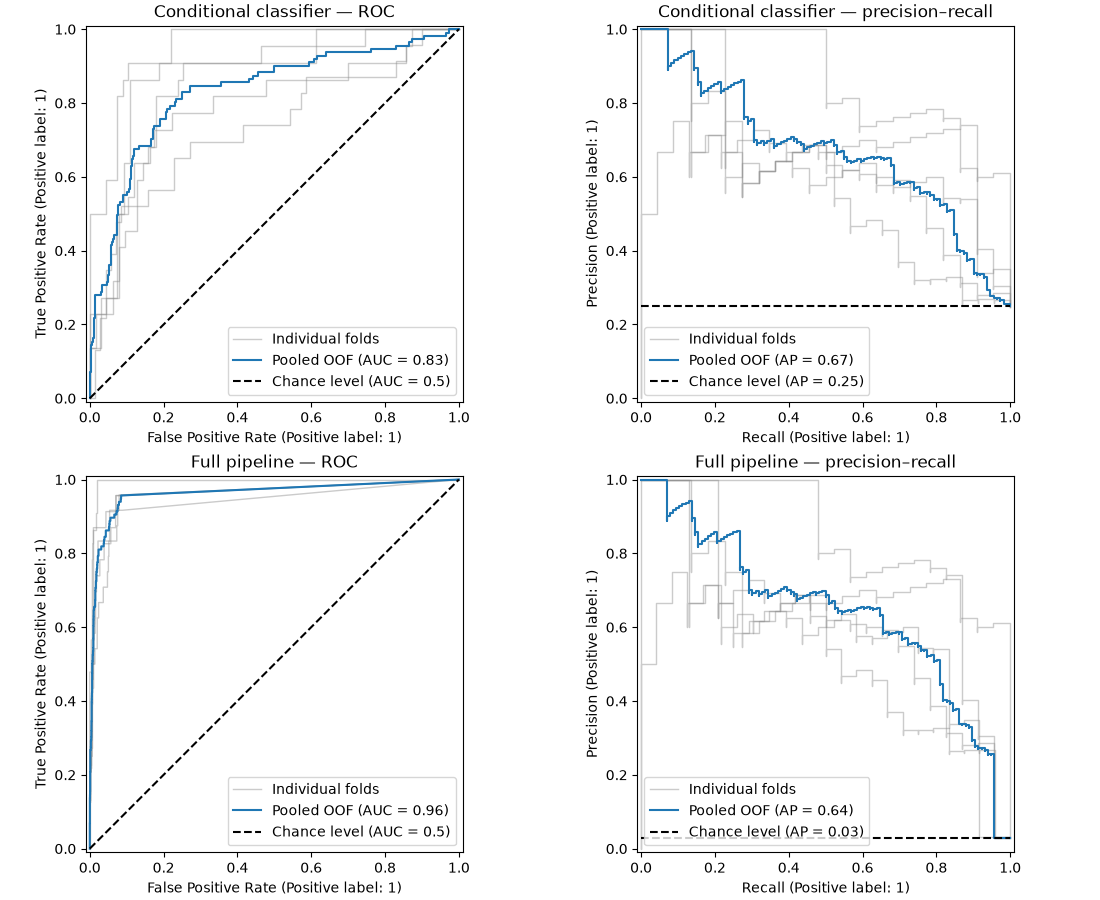

In [131]:
# %% Configuration
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import expit
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

CSV = Path("roi_train2_stage6_sweep_dicece_wts_run1-features_df.csv")
# In your existing notebook: CSV = f"{experiment.id.replace('/', '-')}-features_df.csv"
CLF = "LR"
SEED = 42
FEATURES = ["my_features_" + suffix for suffix in (
    "rim_volume_infer", "rim_hull_volume_infer", "rim_sphere_radius_infer",
    "pca_size", "pca_sphericity", "pca_planarity", "pca_linearity",
    "mean_radius", "std_radius", "min_radius", "max_radius", "radial_cv",
)]

# %% Prepare lesion-level data
data = pd.read_csv(CSV).set_index(["subid", "lesion_index"], verify_integrity=True)
data = data.loc[data.case_type.isin(["PRL", "Lesion"])].copy()
screen = data.has_iron_infer.fillna(False)
if not pd.api.types.is_bool_dtype(screen):
    raise ValueError("Expected Boolean has_iron_infer values.")
oof = pd.DataFrame({"y_true": data.case_type.eq("PRL"), "screen": screen})
oof["score"] = 0.0  # Hard screen for lesions with no predicted rim
print(pd.crosstab(data.case_type, screen))
print(f"Screen sensitivity: {screen[oof.y_true].mean():.1%}")

# %% Cross-validation: hold out subjects, train and score only screen positives
classifiers = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                 class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}
model = make_pipeline(SimpleImputer(strategy="constant", fill_value=0),
                      StandardScaler(), classifiers[CLF])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
subjects = data.index.get_level_values("subid")
# Balance candidate PRLs and candidate non-PRLs while assigning all subjects.
strata = data.case_type.where(screen, "screened out")
for fold, (train, test) in enumerate(cv.split(data, strata, groups=subjects), 1):
    train_ids = data.index[train][screen.iloc[train].to_numpy()]
    test_ids = data.index[test][screen.iloc[test].to_numpy()]
    oof.loc[data.index[test], "fold"] = fold
    model.fit(data.loc[train_ids, FEATURES], oof.loc[train_ids, "y_true"])
    if len(test_ids):
        X_test = data.loc[test_ids, FEATURES]
        if CLF == "SVM":
            # Map margins to positive ranking scores above screen rejects.
            scores = expit(model.decision_function(X_test))
        else:
            scores = model.predict_proba(X_test)[:, 1]
        oof.loc[test_ids, "score"] = scores
oof["fold"] = oof["fold"].astype(int)

# %% ROC and precision-recall curves: individual folds and pooled predictions
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
rows = []
for (name, frame), (roc_ax, pr_ax) in zip(
    [("Conditional classifier", oof.loc[screen]), ("Full pipeline", oof)], axes
):
    for fold, subset in frame.groupby("fold"):
        if subset.y_true.nunique() < 2:
            continue  # ROC AUC is undefined for a single-class fold.
        style = {"color": "0.55", "alpha": 0.45, "lw": 1,
                 "label": "Individual folds" if fold == 1 else "_nolegend_"}
        RocCurveDisplay.from_predictions(subset.y_true, subset.score, ax=roc_ax, curve_kwargs=style)
        PrecisionRecallDisplay.from_predictions(subset.y_true, subset.score, ax=pr_ax, **style)
    RocCurveDisplay.from_predictions(frame.y_true, frame.score, ax=roc_ax,
                                     name="Pooled OOF", plot_chance_level=True)
    PrecisionRecallDisplay.from_predictions(frame.y_true, frame.score, ax=pr_ax,
                                            name="Pooled OOF", plot_chance_level=True)
    roc_ax.set_title(f"{name} — ROC")
    pr_ax.set_title(f"{name} — precision–recall")
    rows.append({"Evaluation": name, "Lesions": len(frame), "PRLs": frame.y_true.sum(),
                 "ROC AUC": roc_auc_score(frame.y_true, frame.score),
                 "AP": average_precision_score(frame.y_true, frame.score)})
metrics = pd.DataFrame(rows).set_index("Evaluation")
print(metrics.round(3))
plt.show()


In [ ]:
for fold, (train_idx, val_idx) in enumerate(cv.split(data[FEATURES], data['y_true'])):
    train_df = scree
# Split the DataFrames directly: their MultiIndex is retained.
train_df, test_df = train_test_split(
    screened_in,
    test_size=TEST_SIZE,
    stratify=screened_in["y_true"],
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", classifiers[CLF]),
])

model.fit(train_df[FEATURES], train_df["y_true"])

print(f"\nTrain: {len(train_df)} ({train_df.y_true.sum()} PRLs)")
print(f"Test:  {len(test_df)} ({test_df.y_true.sum()} PRLs)")

# %% Conditional classifier predictions

# Predictions for lesions that passed the rim screen.
conditional_test = test_df[["y_true"]].copy()
conditional_test["score"] = model.predict_proba(test_df[FEATURES])[:, 1]

# %% Full-pipeline predictions

# Sample the same fraction of screened-out lesions.
rejected_test = screened_out.sample(
    frac=TEST_SIZE,
    random_state=RANDOM_STATE,
)[["y_true"]].copy()

# Hard screening rule: lesions without predicted rims receive score 0.
rejected_test["score"] = 0.0

# Combine both sets while preserving (subid, lesion_index).
pipeline_test = pd.concat([conditional_test, rejected_test])
pipeline_test = pipeline_test.sort_index()

print(
    f"\nFull pipeline test: {len(pipeline_test)} lesions "
    f"({pipeline_test.y_true.sum()} PRLs)"
)

print(
    f"Rejected PRLs in test: {rejected_test.y_true.sum()} "
    f"out of {len(rejected_test)} rejected lesions"
)

# %% Metrics

def evaluate_predictions(predictions, threshold=0.5):
    y_true = predictions["y_true"]
    y_score = predictions["score"]
    y_pred = (y_score >= threshold).astype(int)

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    return {
        "n": len(predictions),
        "n_prl": int(y_true.sum()),
        "prevalence": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, y_score),
        "average_precision": average_precision_score(y_true, y_score), # ! this is like rectangular integration
        # "pr_auc": auc(recall, precision), # ! dont use AUC on PR curve due to issues with interpolating in trapezoidal integration
        "sensitivity": ((y_pred == 1) & (y_true == 1)).sum() / y_true.sum(),
        "specificity": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }


metrics = pd.DataFrame({
    "Conditional classifier": evaluate_predictions(conditional_test),
    "Full pipeline": evaluate_predictions(pipeline_test),
}).T

display(metrics.round(3))

print("\n--- Conditional classifier ---")
print(classification_report(
    conditional_test.y_true,
    (conditional_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

print("\n--- Full pipeline ---")
print(classification_report(
    pipeline_test.y_true,
    (pipeline_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

# %% ROC and precision-recall curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, predictions, color in [
    ("Conditional", conditional_test, "C0"),
    ("Full pipeline", pipeline_test, "C1"),
]:
    RocCurveDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.2)

axes[1].axhline(
    pipeline_test.y_true.mean(),
    color="C1",
    linestyle="--",
    alpha=0.5,
    label="Full-pipeline prevalence",
)
axes[1].axhline(
    conditional_test.y_true.mean(),
    color="C0",
    linestyle=":",
    alpha=0.5,
    label="Conditional prevalence",
)
axes[1].set_title("Precision-recall curve")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

# %% Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, predictions) in zip(
    axes,
    [
        ("Conditional classifier", conditional_test),
        ("Full pipeline", pipeline_test),
    ],
):
    cm = confusion_matrix(
        predictions.y_true,
        (predictions.score >= 0.5).astype(int),
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Lesion", "PRL"],
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [127]:
test_idx.shape[0]/train_idx.shape[0]

0.24858757062146894

---

No kfold (original)

All lesions:  3912 (116 PRLs)
Screened in:  442 (111 PRLs)
Screened out: 3470 (5 PRLs)
Rim-screen sensitivity: 95.7%

Train: 397 (100 PRLs)
Test:  45 (11 PRLs)

Full pipeline test: 392 lesions (11 PRLs)
Rejected PRLs in test: 0 out of 347 rejected lesions


/tmp/ipykernel_2145434/440074728.py:62: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()


,n,n_prl,prevalence,roc_auc,average_precision,sensitivity,specificity
Conditional classifier,45.0,11.0,0.244,0.922,0.857,0.818,0.882
Full pipeline,392.0,11.0,0.028,0.993,0.857,0.818,0.990



--- Conditional classifier ---
              precision    recall  f1-score   support

      Lesion       0.94      0.88      0.91        34
         PRL       0.69      0.82      0.75        11

    accuracy                           0.87        45
   macro avg       0.81      0.85      0.83        45
weighted avg       0.88      0.87      0.87        45


--- Full pipeline ---
              precision    recall  f1-score   support

      Lesion       0.99      0.99      0.99       381
         PRL       0.69      0.82      0.75        11

    accuracy                           0.98       392
   macro avg       0.84      0.90      0.87       392
weighted avg       0.99      0.98      0.99       392



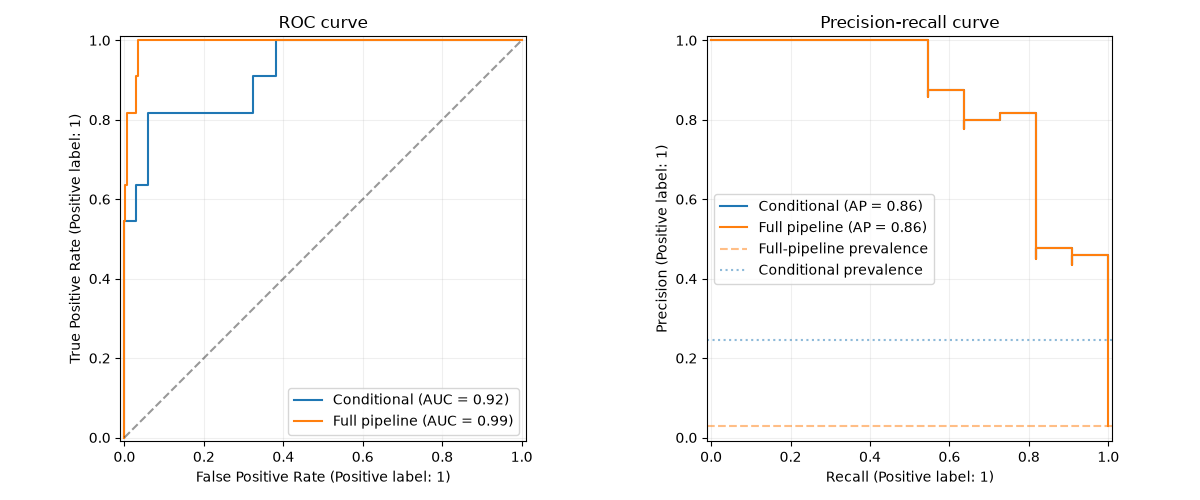

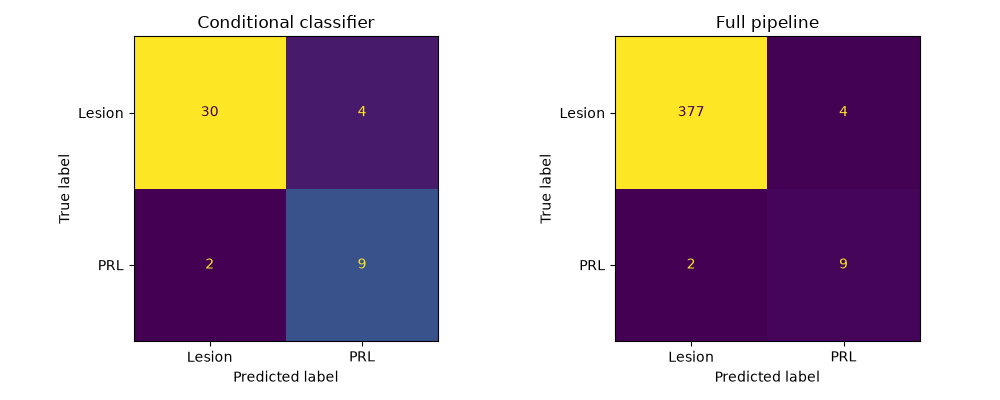

In [132]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = SEED = 42


classifiers = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                    class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
}

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"

TEST_SIZE = 0.10

CLF = "LR"

FEATURES = [
    "my_features_rim_volume_infer",
    "my_features_rim_hull_volume_infer",
    "my_features_rim_sphere_radius_infer",
    "my_features_pca_size",
    "my_features_pca_sphericity",
    "my_features_pca_planarity",
    "my_features_pca_linearity",
    "my_features_mean_radius",
    "my_features_std_radius",
    "my_features_min_radius",
    "my_features_max_radius",
    "my_features_radial_cv",
] + [col for col in df.columns if "pyradiomics_lesion_" in col]

# FEATURES = [
#     "my_features_rim_hull_volume_infer",
# ]

# %% Prepare data
df = pd.read_csv(f"{experiment.id.replace('/', '-')}-features_df.csv")
# Keep lesion identifiers as the DataFrame index throughout.
data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

# Separate lesions by SegResNet screening result.
screened_in = data.loc[data[SCREEN_COL]]
screened_out = data.loc[~data[SCREEN_COL]]

print(f"All lesions:  {len(data)} ({data.y_true.sum()} PRLs)")
print(f"Screened in:  {len(screened_in)} ({screened_in.y_true.sum()} PRLs)")
print(f"Screened out: {len(screened_out)} ({screened_out.y_true.sum()} PRLs)")

screen_sensitivity = screened_in.y_true.sum() / data.y_true.sum()
print(f"Rim-screen sensitivity: {screen_sensitivity:.1%}")

# %% Split and train

# Split the DataFrames directly: their MultiIndex is retained.
train_df, test_df = train_test_split(
    screened_in,
    test_size=TEST_SIZE,
    stratify=screened_in["y_true"],
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", classifiers[CLF]),
])

model.fit(train_df[FEATURES], train_df["y_true"])

print(f"\nTrain: {len(train_df)} ({train_df.y_true.sum()} PRLs)")
print(f"Test:  {len(test_df)} ({test_df.y_true.sum()} PRLs)")

# %% Conditional classifier predictions

# Predictions for lesions that passed the rim screen.
conditional_test = test_df[["y_true"]].copy()
conditional_test["score"] = model.predict_proba(test_df[FEATURES])[:, 1]

# %% Full-pipeline predictions

# Sample the same fraction of screened-out lesions.
rejected_test = screened_out.sample(
    frac=TEST_SIZE,
    random_state=RANDOM_STATE,
)[["y_true"]].copy()

# Hard screening rule: lesions without predicted rims receive score 0.
rejected_test["score"] = 0.0

# Combine both sets while preserving (subid, lesion_index).
pipeline_test = pd.concat([conditional_test, rejected_test])
pipeline_test = pipeline_test.sort_index()

print(
    f"\nFull pipeline test: {len(pipeline_test)} lesions "
    f"({pipeline_test.y_true.sum()} PRLs)"
)

print(
    f"Rejected PRLs in test: {rejected_test.y_true.sum()} "
    f"out of {len(rejected_test)} rejected lesions"
)

# %% Metrics

def evaluate_predictions(predictions, threshold=0.5):
    y_true = predictions["y_true"]
    y_score = predictions["score"]
    y_pred = (y_score >= threshold).astype(int)

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    return {
        "n": len(predictions),
        "n_prl": int(y_true.sum()),
        "prevalence": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, y_score),
        "average_precision": average_precision_score(y_true, y_score), # ! this is like rectangular integration
        # "pr_auc": auc(recall, precision), # ! dont use AUC on PR curve due to issues with interpolating in trapezoidal integration
        "sensitivity": ((y_pred == 1) & (y_true == 1)).sum() / y_true.sum(),
        "specificity": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }


metrics = pd.DataFrame({
    "Conditional classifier": evaluate_predictions(conditional_test),
    "Full pipeline": evaluate_predictions(pipeline_test),
}).T

display(metrics.round(3))

print("\n--- Conditional classifier ---")
print(classification_report(
    conditional_test.y_true,
    (conditional_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

print("\n--- Full pipeline ---")
print(classification_report(
    pipeline_test.y_true,
    (pipeline_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

# %% ROC and precision-recall curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, predictions, color in [
    ("Conditional", conditional_test, "C0"),
    ("Full pipeline", pipeline_test, "C1"),
]:
    RocCurveDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.2)

axes[1].axhline(
    pipeline_test.y_true.mean(),
    color="C1",
    linestyle="--",
    alpha=0.5,
    label="Full-pipeline prevalence",
)
axes[1].axhline(
    conditional_test.y_true.mean(),
    color="C0",
    linestyle=":",
    alpha=0.5,
    label="Conditional prevalence",
)
axes[1].set_title("Precision-recall curve")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

# %% Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, predictions) in zip(
    axes,
    [
        ("Conditional classifier", conditional_test),
        ("Full pipeline", pipeline_test),
    ],
):
    cm = confusion_matrix(
        predictions.y_true,
        (predictions.score >= 0.5).astype(int),
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Lesion", "PRL"],
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [39]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

SEED = 42
X = screened_in[FEATURES]
y = screened_in["y_true"]
groups = screened_in.index.get_level_values("subid")

forest_params = dict(
    n_estimators=250,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)

pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("select", SelectFromModel(
        RandomForestClassifier(**forest_params),
        threshold=-np.inf,  # max_features alone determines how many survive
    )),
    ("rf", RandomForestClassifier(**forest_params)),
])

# "passthrough" lets all 12 features compete against selection.
param_grid = [
    {"select__max_features": [3, 6]},
    {"select": ["passthrough"]},
]

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)

oof = pd.DataFrame(index=X.index)
oof["raw_volume"] = X["my_features_rim_volume_infer"]
oof["selected_rf"] = np.nan
oof["all_features_rf"] = np.nan
selected_by_fold = {}

for fold, (train, test) in enumerate(outer_cv.split(X, y, groups), start=1):
    X_train, X_test = X.iloc[train], X.iloc[test]
    y_train = y.iloc[train]

    search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        scoring="average_precision",
        cv=inner_cv,
        refit=True,
    )
    search.fit(X_train, y_train, groups=groups[train])

    best = search.best_estimator_
    oof.loc[X_test.index, "selected_rf"] = best.predict_proba(X_test)[:, 1]

    selector = best.named_steps["select"]
    if selector == "passthrough":
        selected_by_fold[fold] = X.columns.tolist()
    else:
        selected_by_fold[fold] = X.columns[selector.get_support()].tolist()

    # Fixed all-feature benchmark on exactly the same outer train/test split.
    full = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("rf", RandomForestClassifier(**forest_params)),
    ])
    full.fit(X_train, y_train)
    oof.loc[X_test.index, "all_features_rf"] = full.predict_proba(X_test)[:, 1]

print("Pooled conditional AP")
print(oof.apply(lambda scores: average_precision_score(y, scores)).round(3))

for fold, names in selected_by_fold.items():
    print(f"Fold {fold}: {len(names)} features — {', '.join(names)}")

Pooled conditional AP
raw_volume         0.635
selected_rf        0.645
all_features_rf    0.661
dtype: float64
Fold 1: 12 features — my_features_rim_volume_infer, my_features_rim_hull_volume_infer, my_features_rim_sphere_radius_infer, my_features_pca_size, my_features_pca_sphericity, my_features_pca_planarity, my_features_pca_linearity, my_features_mean_radius, my_features_std_radius, my_features_min_radius, my_features_max_radius, my_features_radial_cv
Fold 2: 12 features — my_features_rim_volume_infer, my_features_rim_hull_volume_infer, my_features_rim_sphere_radius_infer, my_features_pca_size, my_features_pca_sphericity, my_features_pca_planarity, my_features_pca_linearity, my_features_mean_radius, my_features_std_radius, my_features_min_radius, my_features_max_radius, my_features_radial_cv
Fold 3: 12 features — my_features_rim_volume_infer, my_features_rim_hull_volume_infer, my_features_rim_sphere_radius_infer, my_features_pca_size, my_features_pca_sphericity, my_features_pca_plan

In [34]:
df_feat = pd.DataFrame({
    "feature_name": FEATURES,
    "coef": model['clf'].coef_[0]
})

df_feat

,feature_name,coef
0,my_features_rim_volume_infer,2.318562
1,my_features_rim_hull_volume_infer,-1.224865


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    auc,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"

TEST_SIZE = 0.10
RANDOM_STATE = 42

FEATURES = [col for col in df.columns if 'shape_' in col] + [
    "rim_volume_infer",
    "rim_hull_volume_infer",
    "rim_sphere_radius_infer",
    "pca_size",
    "pca_sphericity",
    "pca_planarity",
    "pca_linearity",
    "mean_radius",
    "std_radius",
    "min_radius",
    "max_radius",
    "radial_cv",
]

# %% Prepare data

# Keep lesion identifiers as the DataFrame index throughout.
data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

# Separate lesions by SegResNet screening result.
screened_in = data.loc[data[SCREEN_COL]]
screened_out = data.loc[~data[SCREEN_COL]]

print(f"All lesions:  {len(data)} ({data.y_true.sum()} PRLs)")
print(f"Screened in:  {len(screened_in)} ({screened_in.y_true.sum()} PRLs)")
print(f"Screened out: {len(screened_out)} ({screened_out.y_true.sum()} PRLs)")

screen_sensitivity = screened_in.y_true.sum() / data.y_true.sum()
print(f"Rim-screen sensitivity: {screen_sensitivity:.1%}")

# %% Split and train

# Split the DataFrames directly: their MultiIndex is retained.
train_df, test_df = train_test_split(
    screened_in,
    test_size=TEST_SIZE,
    stratify=screened_in["y_true"],
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

model.fit(train_df[FEATURES], train_df["y_true"])

print(f"\nTrain: {len(train_df)} ({train_df.y_true.sum()} PRLs)")
print(f"Test:  {len(test_df)} ({test_df.y_true.sum()} PRLs)")

# %% Conditional classifier predictions

# Predictions for lesions that passed the rim screen.
conditional_test = test_df[["y_true"]].copy()
conditional_test["score"] = model.predict_proba(test_df[FEATURES])[:, 1]

# %% Full-pipeline predictions

# Sample the same fraction of screened-out lesions.
rejected_test = screened_out.sample(
    frac=TEST_SIZE,
    random_state=RANDOM_STATE,
)[["y_true"]].copy()

# Hard screening rule: lesions without predicted rims receive score 0.
rejected_test["score"] = 0.0

# Combine both sets while preserving (subid, lesion_index).
pipeline_test = pd.concat([conditional_test, rejected_test])
pipeline_test = pipeline_test.sort_index()

print(
    f"\nFull pipeline test: {len(pipeline_test)} lesions "
    f"({pipeline_test.y_true.sum()} PRLs)"
)

print(
    f"Rejected PRLs in test: {rejected_test.y_true.sum()} "
    f"out of {len(rejected_test)} rejected lesions"
)

# %% Metrics

def evaluate_predictions(predictions, threshold=0.5):
    y_true = predictions["y_true"]
    y_score = predictions["score"]
    y_pred = (y_score >= threshold).astype(int)

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    return {
        "n": len(predictions),
        "n_prl": int(y_true.sum()),
        "prevalence": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, y_score),
        "average_precision": average_precision_score(y_true, y_score),
        "pr_auc": auc(recall, precision),
        "sensitivity": ((y_pred == 1) & (y_true == 1)).sum() / y_true.sum(),
        "specificity": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }


metrics = pd.DataFrame({
    "Conditional classifier": evaluate_predictions(conditional_test),
    "Full pipeline": evaluate_predictions(pipeline_test),
}).T

display(metrics.round(3))

print("\n--- Conditional classifier ---")
print(classification_report(
    conditional_test.y_true,
    (conditional_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

print("\n--- Full pipeline ---")
print(classification_report(
    pipeline_test.y_true,
    (pipeline_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

# %% ROC and precision-recall curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, predictions, color in [
    ("Conditional", conditional_test, "C0"),
    ("Full pipeline", pipeline_test, "C1"),
]:
    RocCurveDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        curve_kwargs={
            "color":color,
        },
        ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.2)

axes[1].axhline(
    pipeline_test.y_true.mean(),
    color="C1",
    linestyle="--",
    alpha=0.5,
    label="Full-pipeline prevalence",
)
axes[1].axhline(
    conditional_test.y_true.mean(),
    color="C0",
    linestyle=":",
    alpha=0.5,
    label="Conditional prevalence",
)
axes[1].set_title("Precision-recall curve")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

# %% Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, predictions) in zip(
    axes,
    [
        ("Conditional classifier", conditional_test),
        ("Full pipeline", pipeline_test),
    ],
):
    cm = confusion_matrix(
        predictions.y_true,
        (predictions.score >= 0.5).astype(int),
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Lesion", "PRL"],
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


/tmp/ipykernel_2145434/1541037573.py:45: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()


All lesions:  3912 (116 PRLs)
Screened in:  442 (111 PRLs)
Screened out: 3470 (5 PRLs)
Rim-screen sensitivity: 95.7%


KeyError: "['rim_volume_infer', 'rim_hull_volume_infer', 'rim_sphere_radius_infer', 'pca_size', 'pca_sphericity', 'pca_planarity', 'pca_linearity', 'mean_radius', 'std_radius', 'min_radius', 'max_radius', 'radial_cv'] not in index"

In [ ]:
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score as ap, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42


def analyze(csv_path):
    lesions = pd.read_csv(csv_path).set_index(["subid", "lesion_index"], verify_integrity=True)
    lesions = lesions.loc[lesions.case_type.isin(["PRL", "Lesion"])]
    screen = lesions.has_iron_infer.fillna(False)
    if not pd.api.types.is_bool_dtype(screen):
        raise ValueError("Expected a Boolean has_iron_infer column.")
    candidates = lesions.loc[screen]
    truth = lesions.case_type.eq("PRL").to_numpy()
    y = truth[screen]
    subjects = candidates.index.get_level_values("subid")
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(splitter.split(candidates, y, subjects))

    custom = ["my_features_" + suffix for suffix in (
        "rim_volume_infer", "rim_hull_volume_infer", "rim_sphere_radius_infer",
        "pca_size", "pca_sphericity", "pca_planarity", "pca_linearity",
        "mean_radius", "std_radius", "min_radius", "max_radius", "radial_cv",
    )]
    radio = list(candidates.filter(regex="^pyradiomics_"))
    shape = list(candidates.filter(regex="^pyradiomics_shape_"))
    sets = {
        "Volume": custom[:1], "Custom": custom, "Shape": shape,
        "Texture": [col for col in radio if col not in shape],
        "PyRadiomics": radio, "Combined": custom + radio,
    }
    subsets = {
        "Volume + hull + sphere": custom[:3], "PCA": custom[3:7],
        "Radial": custom[7:], "Volume + radial": custom[:1] + custom[7:],
    }
    models = {
        "LR": LogisticRegression(class_weight="balanced", max_iter=2000),
        "RF": RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1),
        "SVM": SVC(kernel="rbf", class_weight="balanced"),
    }

    def summarize(name, model, scores, decisions=None):
        full_scores = np.zeros(len(lesions))
        full_scores[screen] = scores
        row = dict(features=name, model=model, conditional_AP=ap(y, scores),
                   conditional_AUC=roc_auc_score(y, scores), full_AP=ap(truth, full_scores),
                   full_AUC=roc_auc_score(truth, full_scores))
        if decisions is not None:
            tp = int(np.sum(y & decisions))
            fp = int(np.sum(~y & decisions))
            row.update(TP=tp, FP=fp, sensitivity=tp / truth.sum(),
                       precision=tp / (tp + fp) if tp + fp else np.nan)
        return row

    rows = [summarize("Volume", "Raw ranking", candidates[custom[0]])]
    lr_scores = {}
    for name, columns in (sets | subsets).items():
        for key, estimator in models.items():
            if name in subsets and key != "LR":
                continue
            scores = np.empty(len(y))
            decisions = np.empty(len(y), dtype=bool)
            features = candidates[columns]
            for train, test in folds:
                pipeline = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                         StandardScaler(), estimator)
                pipeline.fit(features.iloc[train], y[train])
                held_out = features.iloc[test]
                if key == "SVM":
                    # Positive ranking scores above the zero assigned to rejected lesions.
                    # This monotonic transform does not calibrate probabilities.
                    scores[test] = expit(pipeline.decision_function(held_out))
                else:
                    scores[test] = pipeline.predict_proba(held_out)[:, 1]
                decisions[test] = pipeline.predict(held_out)
            rows.append(summarize(name, key, scores, decisions))
            if key == "LR":
                lr_scores[name] = scores

    print(f"Screen retained {sum(y)}/{sum(truth)} PRLs and {sum(~y)} non-PRLs.")
    print(pd.DataFrame(rows).round(3).to_string(index=False))

    # Resample subjects with replacement using the same draws for both models.
    groups = [np.flatnonzero(subjects == subject) for subject in subjects.unique()]
    rng = np.random.default_rng(SEED)
    comparisons = ["Shape", "PyRadiomics", "Combined", "Volume"]
    differences = []
    for _ in range(2000):
        draw = rng.integers(len(groups), size=len(groups))
        idx = np.concatenate([groups[j] for j in draw])
        custom_ap = ap(y[idx], lr_scores["Custom"][idx])
        differences.append([custom_ap - ap(y[idx], lr_scores[name][idx]) for name in comparisons])
    intervals = pd.DataFrame(np.quantile(differences, [0.025, 0.975], axis=0).T,
                             index=comparisons, columns=["lower", "upper"])
    print("\nPaired 95% bootstrap intervals for conditional AP (custom LR minus comparator LR)")
    print(intervals.round(3))





In [15]:
analyze("/home/srs-9/Projects/prl_project/notebooks/roi_train2_stage6_sweep_dicece_wts_run1-features_df.csv")

/tmp/ipykernel_2145434/2334428004.py:17: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  lesions = pd.read_csv(csv_path).set_index(["subid", "lesion_index"], verify_integrity=True)


Screen retained 111/116 PRLs and 331 non-PRLs.
              features       model  conditional_AP  conditional_AUC  full_AP  full_AUC   TP    FP  sensitivity  precision
                Volume Raw ranking           0.635            0.837    0.609     0.963  NaN   NaN          NaN        NaN
                Volume          LR           0.623            0.829    0.597     0.962 70.0  50.0        0.603      0.583
                Volume          RF           0.448            0.739    0.418     0.932 79.0  93.0        0.681      0.459
                Volume         SVM           0.510            0.801    0.489     0.960 78.0  63.0        0.672      0.553
                Custom          LR           0.658            0.842    0.631     0.963 84.0  64.0        0.724      0.568
                Custom          RF           0.645            0.828    0.619     0.962 80.0  60.0        0.690      0.571
                Custom         SVM           0.662            0.827    0.635     0.962 82.0  61.0  

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [11]:
TARGET = "case_type"        # "PRL" or "Lesion"
POS_LABEL = "PRL"

TEST_SIZE = 0.25            # fraction held out
RANDOM_STATE = 42
CV_FOLDS = 5

# FEATURES = [col for col in all_features.columns if 'shape' in col]
FEATURES = [
    "rim_volume_infer",
    "rim_hull_volume_infer",
    "rim_sphere_radius_infer",
    "pca_size",
    "pca_sphericity",

    "pca_planarity",
    "pca_linearity",
    "mean_radius",
    "std_radius",
    "min_radius",
    "max_radius",
    "radial_cv",
]

In [24]:
TEST_SIZE = 0.1            # fraction held out

model_df = df[df.has_iron_infer].copy()
print(f"Loaded {len(model_df)} rows | {model_df[TARGET].value_counts().to_dict()}")

X = model_df[['subid', 'lesion_index']+FEATURES].values
y = (model_df[TARGET] == POS_LABEL).astype(int).values   # 1 = PRL, 0 = Lesion

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(y_train)} ({y_train.sum()} PRL) | Test: {len(y_test)} ({y_test.sum()} PRL)")

index_train = X_train[:, :2]
index_test = X_test[:, :2]
X_train = X_train[:, 2:]
X_test = X_test[:, 2:]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),   # hull/sphere NaN when <4 rim voxels
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",    # important: 48 PRL vs ~117 Lesion
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

model.fit(X_train, y_train)

Loaded 442 rows | {'Lesion': 331, 'PRL': 111}
Train: 397 (100 PRL) | Test: 45 (11 PRL)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",0
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If


--- Test set ---
              precision    recall  f1-score   support

      Lesion       0.94      0.85      0.89        34
         PRL       0.64      0.82      0.72        11

    accuracy                           0.84        45
   macro avg       0.79      0.84      0.81        45
weighted avg       0.86      0.84      0.85        45

ROC-AUC: 0.864


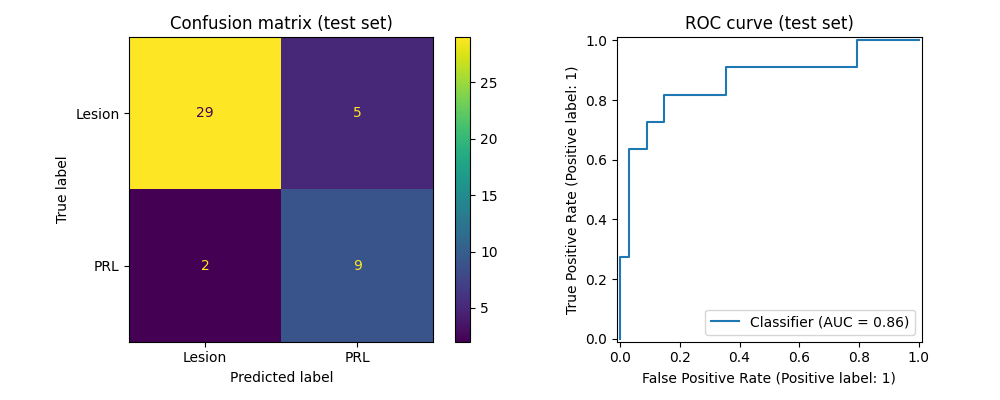

In [25]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\n--- Test set ---")
print(classification_report(y_test, y_pred, target_names=["Lesion", "PRL"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Lesion", "PRL"]).plot(ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_prob, pos_label=1, ax=axes[1])
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

In [ ]:
df = cases.reset_index().merge(
    feature_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)
df = df[df.split == "testing"]
df